# 🐄 VETRA: Vision-Enabled Type Recording Assistant

In [ ]:
# Path setup: notebooks live in notebooks/, but every path below is relative to the repo root
import os
from pathlib import Path

_here = Path.cwd()
for _cand in (_here, *_here.parents):
    if (_cand / "README.md").exists() and (_cand / "notebooks").is_dir():
        os.chdir(_cand)
        break
print("Working directory:", Path.cwd())

In [85]:
# ==============================
# STEP 1.1: IMPORT LIBRARIES AND SETUP
# ==============================
import os
import yaml
import shutil
import random
from sklearn.model_selection import train_test_split
from ultralytics import YOLO
import matplotlib.pyplot as plt
%matplotlib inline 

print("🔧 Initializing VETRA - Animal Type Classification System")
print("=" * 60)

🔧 Initializing VETRA - Animal Type Classification System


In [8]:
# ==============================
# STEP 1.2: CONFIGURATION SETTINGS
# ==============================
# Define all configuration parameters
CONFIG = {
    # Paths
    'data_root': 'data',
    'side_view_images': 'data/side_view',
    'back_view_images': 'data/back_view', 
    'side_view_labels': 'data/labels_side',
    'back_view_labels': 'data/labels-back',
    
    # YOLO Training Parameters
    'model_name': 'models/pretrained/yolov8n-pose.pt',
    'epochs': 200,
    'imgsz': 640,
    'batch_size': 16,
    'patience': 50,
    
    # Data split
    'test_size': 0.2,
    'val_size': 0.1,
    'random_state': 42
}

# Create required directories
os.makedirs('runs/side_view', exist_ok=True)
os.makedirs('runs/back_view', exist_ok=True)
os.makedirs('temp', exist_ok=True)

print("✅ Configuration loaded and directories created")

✅ Configuration loaded and directories created


In [3]:
# ==============================
# STEP 1.3: DATA EXPLORATION AND VALIDATION
# ==============================
def explore_dataset():
    """Explore and validate the dataset structure"""
    print("\n📊 DATASET EXPLORATION")
    print("-" * 40)
    
    # Check side view data
    side_images = [f for f in os.listdir(CONFIG['side_view_images']) 
                   if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    side_labels = [f for f in os.listdir(CONFIG['side_view_labels']) 
                   if f.endswith('.txt')]
    
    # Check back view data  
    back_images = [f for f in os.listdir(CONFIG['back_view_images'])
                   if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    back_labels = [f for f in os.listdir(CONFIG['back_view_labels'])
                   if f.endswith('.txt')]
    
    print(f"Side View - Images: {len(side_images)}, Labels: {len(side_labels)}")
    print(f"Back View - Images: {len(back_images)}, Labels: {len(back_labels)}")
    
    # Check for matching files
    side_image_ids = {os.path.splitext(f)[0] for f in side_images}
    side_label_ids = {os.path.splitext(f)[0] for f in side_labels}
    side_matched = side_image_ids & side_label_ids
    
    back_image_ids = {os.path.splitext(f)[0] for f in back_images}
    back_label_ids = {os.path.splitext(f)[0] for f in back_labels}
    back_matched = back_image_ids & back_label_ids
    
    print(f"\n✅ Matched pairs:")
    print(f"   Side View: {len(side_matched)} pairs")
    print(f"   Back View: {len(back_matched)} pairs")
    
    return side_images, back_images

# Run exploration
side_images, back_images = explore_dataset()


📊 DATASET EXPLORATION
----------------------------------------
Side View - Images: 138, Labels: 138
Back View - Images: 72, Labels: 72

✅ Matched pairs:
   Side View: 137 pairs
   Back View: 72 pairs


In [4]:
# ==============================
# STEP 1.4: CREATE TRAIN/VAL/TEST SPLITS
# ==============================
def create_data_splits(view_type, image_files):
    """Create train/val/test splits for YOLO training"""
    print(f"\n🔄 Creating data splits for {view_type} view...")
    
    # Remove extensions to get base names
    base_names = [os.path.splitext(f)[0] for f in image_files]
    
    # Split data: 70% train, 20% test, 10% val
    train_val_names, test_names = train_test_split(
        base_names, test_size=CONFIG['test_size'], random_state=CONFIG['random_state']
    )
    train_names, val_names = train_test_split(
        train_val_names, test_size=CONFIG['val_size']/(1-CONFIG['test_size']), 
        random_state=CONFIG['random_state']
    )
    
    print(f"   Train: {len(train_names)} images")
    print(f"   Val: {len(val_names)} images") 
    print(f"   Test: {len(test_names)} images")
    
    return train_names, val_names, test_names

# Create splits for both views
side_train, side_val, side_test = create_data_splits('side', side_images)
back_train, back_val, back_test = create_data_splits('back', back_images)


🔄 Creating data splits for side view...
   Train: 96 images
   Val: 14 images
   Test: 28 images

🔄 Creating data splits for back view...
   Train: 49 images
   Val: 8 images
   Test: 15 images


In [5]:
# ==============================
# STEP 1.5: CREATE YOLO DATA STRUCTURE
# ==============================
def setup_yolo_structure(view_type, train_names, val_names, test_names):
    """Create YOLO directory structure and symlinks"""
    print(f"\n📁 Setting up YOLO structure for {view_type} view...")
    
    # Create directory structure
    yolo_dir = f"yolo_{view_type}"
    os.makedirs(f"{yolo_dir}/images/train", exist_ok=True)
    os.makedirs(f"{yolo_dir}/images/val", exist_ok=True)
    os.makedirs(f"{yolo_dir}/images/test", exist_ok=True)
    os.makedirs(f"{yolo_dir}/labels/train", exist_ok=True)
    os.makedirs(f"{yolo_dir}/labels/val", exist_ok=True)
    os.makedirs(f"{yolo_dir}/labels/test", exist_ok=True)
    
    # Define source paths based on view type
    if view_type == 'side':
        img_source = CONFIG['side_view_images']
        lbl_source = CONFIG['side_view_labels']
        num_keypoints = 10
        skeleton = [[0,9], [2,4], [5,6], [1,7], [1,8], [3,4]]
    else:  # back view
        img_source = CONFIG['back_view_images'] 
        lbl_source = CONFIG['back_view_labels']
        num_keypoints = 8
        skeleton = [[0,1], [2,3], [0,2], [1,3], [4,5], [2,6], [3,7]]
    
    # Create symlinks/copies for each split
    splits = {
        'train': train_names,
        'val': val_names, 
        'test': test_names
    }
    
    for split_name, names in splits.items():
        print(f"   Processing {split_name} set ({len(names)} images)...")
        
        for name in names:
            # Find image file (check multiple extensions)
            img_found = False
            for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
                src_img = os.path.join(img_source, name + ext)
                if os.path.exists(src_img):
                    # Create symlink (or copy on Windows)
                    dst_img = f"{yolo_dir}/images/{split_name}/{name}{ext}"
                    if os.name == 'nt':  # Windows
                        shutil.copy2(src_img, dst_img)
                    else:  # Linux/Mac
                        os.symlink(os.path.abspath(src_img), dst_img)
                    img_found = True
                    break
            
            # Copy label file
            src_lbl = os.path.join(lbl_source, name + '.txt')
            if os.path.exists(src_lbl):
                dst_lbl = f"{yolo_dir}/labels/{split_name}/{name}.txt"
                shutil.copy2(src_lbl, dst_lbl)
    
    return yolo_dir, num_keypoints, skeleton

# Setup YOLO structure for both views
side_yolo_dir, side_kpts, side_skeleton = setup_yolo_structure('side', side_train, side_val, side_test)
back_yolo_dir, back_kpts, back_skeleton = setup_yolo_structure('back', back_train, back_val, back_test)


📁 Setting up YOLO structure for side view...
   Processing train set (96 images)...
   Processing val set (14 images)...
   Processing test set (28 images)...

📁 Setting up YOLO structure for back view...
   Processing train set (49 images)...
   Processing val set (8 images)...
   Processing test set (15 images)...


In [6]:
# ==============================
# STEP 1.6: CREATE YAML CONFIGURATION FILES
# ==============================
def create_yaml_config(view_type, yolo_dir, num_keypoints, skeleton):
    """Create YAML configuration file for YOLO training"""
    print(f"\n📄 Creating YAML config for {view_type} view...")
    
    yaml_content = {
        'path': os.path.abspath(yolo_dir),
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        
        # Keypoint configuration
        'kpt_shape': [num_keypoints, 2],
        'skeleton': skeleton,
        
        # Class names (single class - cow/buffalo)
        'names': ['animal'],
        
        # Metadata
        'num_keypoints': num_keypoints,
        'view_type': view_type
    }
    
    yaml_file = f"{view_type}_view.yaml"
    with open(yaml_file, 'w') as f:
        yaml.dump(yaml_content, f, default_flow_style=None)
    
    print(f"   ✅ YAML config saved: {yaml_file}")
    print(f"   Keypoints: {num_keypoints}, Skeleton pairs: {len(skeleton)}")
    
    return yaml_file

# Create YAML files for both views
side_yaml = create_yaml_config('side', side_yolo_dir, side_kpts, side_skeleton)
back_yaml = create_yaml_config('back', back_yolo_dir, back_kpts, back_skeleton)


📄 Creating YAML config for side view...
   ✅ YAML config saved: side_view.yaml
   Keypoints: 10, Skeleton pairs: 6

📄 Creating YAML config for back view...
   ✅ YAML config saved: back_view.yaml
   Keypoints: 8, Skeleton pairs: 7


In [ ]:
# ==============================
# STEP 1.7: TRAIN YOLO POSE MODELS
# ==============================
def train_yolo_model(view_type, yaml_file, num_keypoints):
    """Train YOLO pose estimation model for specific view"""
    print(f"\n🚀 Training YOLO Model for {view_type.upper()} VIEW")
    print("=" * 50)
    
    # Model configuration
    project_name = f"runs/{view_type}_view"
    model_name = f"yolov8_cow_{view_type}_v1"
    
    print(f"📊 Training Details:")
    print(f"   Model: {CONFIG['model_name']}")
    print(f"   Epochs: {CONFIG['epochs']}")
    print(f"   Image Size: {CONFIG['imgsz']}")
    print(f"   Keypoints: {num_keypoints}")
    print(f"   Project: {project_name}")
    print(f"   Name: {model_name}")
    
    # Load pre-trained model
    model = YOLO(CONFIG['model_name'])
    
    # Train the model
    results = model.train(
        data=yaml_file,
        epochs=CONFIG['epochs'],
        imgsz=CONFIG['imgsz'],
        batch=CONFIG['batch_size'],
        project=project_name,
        name=model_name,
        patience=CONFIG['patience'],
        save=True,
        exist_ok=True,
        verbose=False,
        workers=0,
        device='0'  # Change to 'cpu' if no GPU available
    )
    
    print(f"✅ {view_type.upper()} VIEW training completed!")
    print(f"📁 Results saved in: {project_name}/{model_name}")
    
    return model

# Train both models
print("🎯 STARTING YOLO MODEL TRAINING")
print("=" * 60)

# Train Side View Model
side_model = train_yolo_model('side', side_yaml, side_kpts)

# Train Back View Model  
back_model = train_yolo_model('back', back_yaml, back_kpts)

🎯 STARTING YOLO MODEL TRAINING

🚀 Training YOLO Model for SIDE VIEW
📊 Training Details:
   Model: yolov8n-pose.pt
   Epochs: 200
   Image Size: 640
   Keypoints: 10
   Project: runs/side_view
   Name: yolov8_cow_side_v1
Ultralytics 8.3.203  Python-3.11.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=side_view.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mi


📈 Plotting training results for side view...


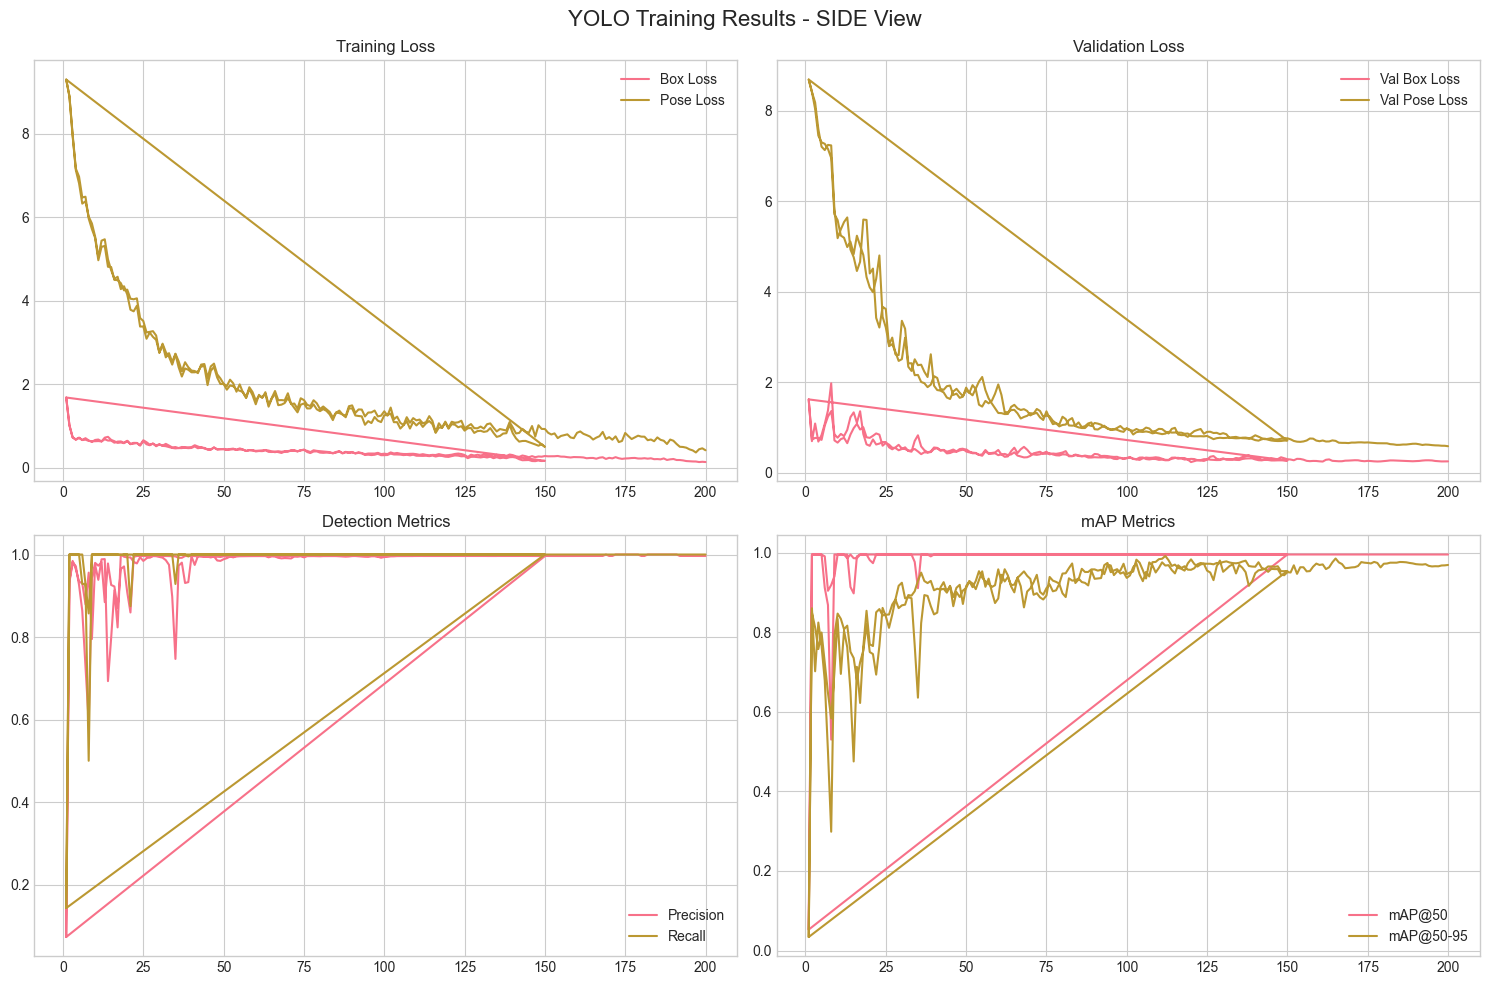


📈 Plotting training results for back view...


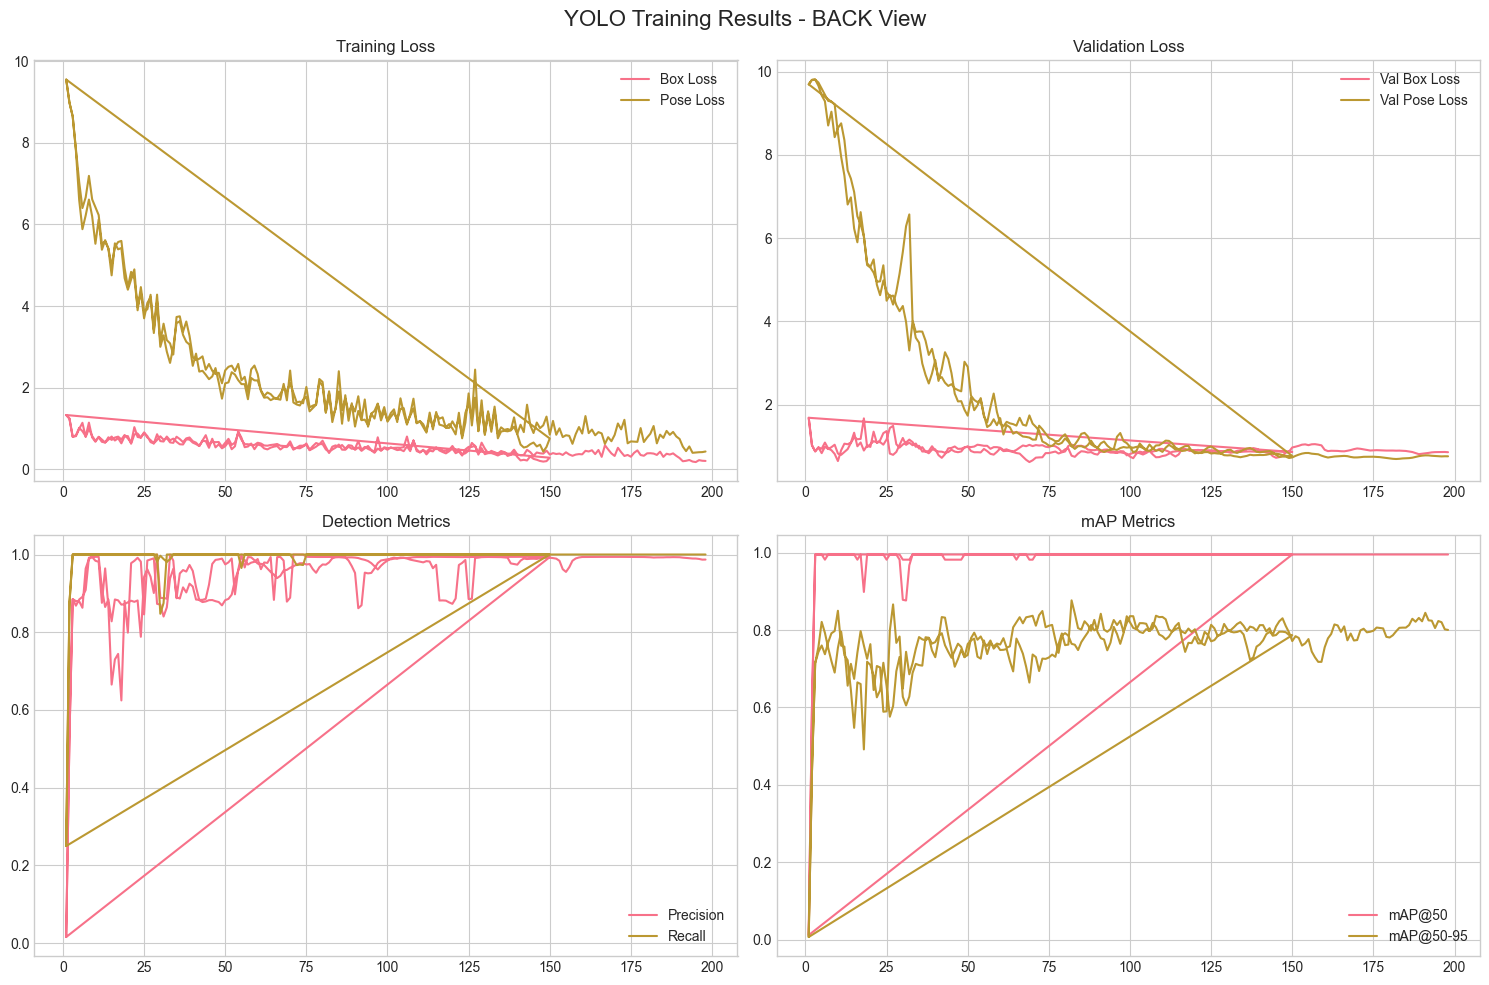

In [86]:
# ==============================
# STEP 1.8: MODEL PERFORMANCE VISUALIZATION
# ==============================
def plot_training_results(view_type):
    """Plot training results for visualization"""
    print(f"\n📈 Plotting training results for {view_type} view...")
    
    results_dir = f"runs/{view_type}_view/yolov8_cow_{view_type}_v1"
    results_file = os.path.join(results_dir, "results.csv")
    
    if os.path.exists(results_file):
        import pandas as pd
        results_df = pd.read_csv(results_file)
        
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        fig.suptitle(f'YOLO Training Results - {view_type.upper()} View', fontsize=16)
        
        # Plot loss curves
        axes[0,0].plot(results_df['epoch'], results_df['train/box_loss'], label='Box Loss')
        axes[0,0].plot(results_df['epoch'], results_df['train/pose_loss'], label='Pose Loss')
        axes[0,0].set_title('Training Loss')
        axes[0,0].legend()
        axes[0,0].grid(True)
        
        axes[0,1].plot(results_df['epoch'], results_df['val/box_loss'], label='Val Box Loss')
        axes[0,1].plot(results_df['epoch'], results_df['val/pose_loss'], label='Val Pose Loss')
        axes[0,1].set_title('Validation Loss')
        axes[0,1].legend()
        axes[0,1].grid(True)
        
        # Plot metrics
        axes[1,0].plot(results_df['epoch'], results_df['metrics/precision(B)'], label='Precision')
        axes[1,0].plot(results_df['epoch'], results_df['metrics/recall(B)'], label='Recall')
        axes[1,0].set_title('Detection Metrics')
        axes[1,0].legend()
        axes[1,0].grid(True)
        
        axes[1,1].plot(results_df['epoch'], results_df['metrics/mAP50(B)'], label='mAP@50')
        axes[1,1].plot(results_df['epoch'], results_df['metrics/mAP50-95(B)'], label='mAP@50-95')
        axes[1,1].set_title('mAP Metrics')
        axes[1,1].legend()
        axes[1,1].grid(True)
        
        plt.tight_layout()
        plt.savefig(f'{view_type}_training_results.jpg', dpi=150, bbox_inches='tight')
        plt.show()
    else:
        print(f"   ⚠️ Results file not found: {results_file}")

# Plot results for both models
plot_training_results('side')
plot_training_results('back')

In [11]:
# ==============================
# STEP 1.9: MODEL VALIDATION AND TESTING
# ==============================
def validate_model(view_type, model):
    """Validate trained model on test set"""
    print(f"\n🧪 Validating {view_type} view model...")
    
    # Run validation
    results = model.val(
        split='test',
        imgsz=CONFIG['imgsz'],
        verbose=False
    )
    
    print(f"✅ {view_type.upper()} VIEW Validation Results:")
    print(f"   Precision: {results.box.map50:.3f}")
    print(f"   Recall: {results.box.map:.3f}")
    print(f"   mAP@50: {results.box.map50:.3f}")
    print(f"   mAP@50-95: {results.box.map:.3f}")
    
    return results

# Validate both models
side_results = validate_model('side', side_model)
back_results = validate_model('back', back_model)


🧪 Validating side view model...
Ultralytics 8.3.203  Python-3.11.3 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
YOLOv8n-pose summary (fused): 81 layers, 3,098,663 parameters, 0 gradients, 8.4 GFLOPs
val: Fast image access  (ping: 0.20.0 ms, read: 279.5236.4 MB/s, size: 4858.3 KB)
val: Scanning D:\Projects\VETRA\Codes\VETRA v2.0\yolo_side\labels\test... 27 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 28/28 60.1it/s 0.5s0.7s
val: New cache created: D:\Projects\VETRA\Codes\VETRA v2.0\yolo_side\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 0.4it/s 4.7s8.4s
                   all         28         27      0.964          1       0.97      0.935      0.964          1       0.97      0.871
Speed: 1.7ms preprocess, 12.7ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to D:\Projects\VETRA\Codes\VETRA v2.0\runs\sid

In [20]:
# ==============================
# STEP 2.8: KEYPOINT STATISTICS ANALYSIS
# ==============================
def analyze_keypoint_statistics():
    """Analyze keypoint detection statistics"""
    print("\n📊 Analyzing Keypoint Detection Statistics...")
    
    stats = {'side': {}, 'back': {}}
    
    # Analyze side view
    if side_model:
        side_detections = 0
        side_keypoints_count = []
        
        for img_path in side_sample_images:
            results = side_model.predict(img_path, imgsz=640, conf=0.3)
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                side_detections += 1
                side_keypoints_count.append(len(keypoints))
        
        stats['side'] = {
            'detection_rate': side_detections / len(side_sample_images),
            'avg_keypoints': np.mean(side_keypoints_count) if side_keypoints_count else 0,
            'total_samples': len(side_sample_images)
        }
    
    # Analyze back view
    if back_model:
        back_detections = 0
        back_keypoints_count = []
        
        for img_path in back_sample_images:
            results = back_model.predict(img_path, imgsz=640, conf=0.3)
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                back_detections += 1
                back_keypoints_count.append(len(keypoints))
        
        stats['back'] = {
            'detection_rate': back_detections / len(back_sample_images),
            'avg_keypoints': np.mean(back_keypoints_count) if back_keypoints_count else 0,
            'total_samples': len(back_sample_images)
        }
    
    # Print statistics
    print("📈 KEYPOINT DETECTION STATISTICS:")
    print("-" * 50)
    for view_type, data in stats.items():
        if data:
            print(f"{view_type.upper()} VIEW:")
            print(f"  Detection Rate: {data['detection_rate']:.1%}")
            print(f"  Average Keypoints: {data['avg_keypoints']:.1f}")
            print(f"  Samples Analyzed: {data['total_samples']}")
            print()
    
    return stats

# Run statistics analysis
keypoint_stats = analyze_keypoint_statistics()


📊 Analyzing Keypoint Detection Statistics...

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0\data\side_view\36.png: 480x640 1 animal, 38.2ms
Speed: 4.8ms preprocess, 38.2ms inference, 5.7ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0\data\side_view\16.png: 480x640 1 animal, 38.2ms
Speed: 4.8ms preprocess, 38.2ms inference, 1.8ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0\data\side_view\85.jpg: 480x640 1 animal, 37.8ms
Speed: 5.3ms preprocess, 37.8ms inference, 2.2ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0\data\side_view\1.png: 480x640 1 animal, 37.8ms
Speed: 4.9ms preprocess, 37.8ms inference, 2.4ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 d:\Projects\VETRA\Codes\VETRA v2.0\data\side_view\125.jpg: 480x640 1 animal, 38.0ms
Speed: 4.9ms preprocess, 38.0ms inference, 2.6ms postprocess per image at shape (1, 3, 480, 640)

In [21]:
# ==============================
# STEP 2.9: MEASUREMENT LANDMARK EXPLANATION
# ==============================
def display_measurement_explanations():
    """Display explanation of measurement landmarks"""
    print("\n📐 MEASUREMENT LANDMARK EXPLANATIONS")
    print("=" * 60)
    
    print("\n🔵 SIDE VIEW MEASUREMENTS (10 Keypoints):")
    print("-" * 40)
    for (i, j), measurement in VIS_CONFIG['side_connections'].items():
        print(f"  Keypoints {i}-{j}: {measurement}")
    
    print("\n🔴 BACK VIEW MEASUREMENTS (8 Keypoints):")
    print("-" * 40)
    for (i, j), measurement in VIS_CONFIG['back_connections'].items():
        print(f"  Keypoints {i}-{j}: {measurement}")
    
    print("\n🎯 KEYPOINT NUMBERING:")
    print("Side View: 0-9 (10 points) | Back View: 0-7 (8 points)")
    print("Each number represents a specific anatomical landmark")

# Display explanations
display_measurement_explanations()


📐 MEASUREMENT LANDMARK EXPLANATIONS

🔵 SIDE VIEW MEASUREMENTS (10 Keypoints):
----------------------------------------
  Keypoints 0-9: Head Length
  Keypoints 2-4: Oblique Body Length
  Keypoints 5-6: Girth Length
  Keypoints 1-7: Chest Depth
  Keypoints 1-8: Wither Height
  Keypoints 3-4: Rump Angle

🔴 BACK VIEW MEASUREMENTS (8 Keypoints):
----------------------------------------
  Keypoints 0-1: Rump Width
  Keypoints 2-3: Hip Width
  Keypoints 4-5: Tail Length
  Keypoints 2-6: Left Hip Height
  Keypoints 3-7: Right Hip Height
  Keypoints 0-2: Thurl Width (L)
  Keypoints 1-3: Thurl Width (R)

🎯 KEYPOINT NUMBERING:
Side View: 0-9 (10 points) | Back View: 0-7 (8 points)
Each number represents a specific anatomical landmark
